# CIC-IDS2017 — Dataset audit and EDA (Kaggle CSV edition)

Reads the 8 CSV files directly from the Kaggle input dataset, without creating a ZIP. Reports and plots are saved under `/kaggle/working/nids_outputs/01_CIC_EDA`. This version performs EDA and sampling only; it does **not** train models or imply leakage-safe evaluation. The supplied CSVs lack timestamp/IP/flow identifiers.

In [12]:
from pathlib import Path
import sys, os, json
import pandas as pd
import numpy as np

# Kaggle inputs are read-only; notebooks save reports to /kaggle/working.
KAGGLE_INPUT = Path('/kaggle/input')
ROOT = Path('/kaggle/working/NIDS-SE-AT-CNN') if Path('/kaggle/working/NIDS-SE-AT-CNN/src').exists() else Path.cwd()
if not (ROOT / 'src' / 'nids').exists():
    candidates = [p.parent for p in KAGGLE_INPUT.rglob('src/nids/training.py')] if KAGGLE_INPUT.exists() else []
    candidates = [p.parent.parent for p in candidates]  # root containing src/
    if candidates:
        ROOT = candidates[0]
if not (ROOT / 'src' / 'nids').exists():
    raise FileNotFoundError('Cannot find project source. Run 00_Kaggle_Setup or attach the source dataset first.')
sys.path.insert(0, str(ROOT / 'src'))

# Uploaded dataset is already expanded into eight CSVs.
DEFAULT_CIC_DIR = KAGGLE_INPUT / 'datasets/chienvoo/nids-se-at-cnn-data/CIC-IDS2017'
CIC_DIR = Path(os.getenv('CIC_DIR', str(DEFAULT_CIC_DIR)))
if not CIC_DIR.is_dir() or not list(CIC_DIR.glob('*.csv')):
    matches = [p for p in KAGGLE_INPUT.rglob('CIC-IDS2017') if p.is_dir() and any(p.glob('*.csv'))] if KAGGLE_INPUT.exists() else []
    if not matches:
        raise FileNotFoundError('CIC-IDS2017 CSV directory not found. Attach nids-se-at-cnn-data as Kaggle Input.')
    CIC_DIR = matches[0]
CIC_FILES = sorted(CIC_DIR.glob('*.csv'))
OUTPUT = Path('/kaggle/working/nids_outputs/01_CIC_EDA' if Path('/kaggle/working').exists() else 'reports/notebook_outputs/01_CIC_EDA')
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('CIC directory:', CIC_DIR)
print('CSV files:', len(CIC_FILES))
print('Output:', OUTPUT)
assert len(CIC_FILES) == 8, f'Expected 8 CSV files, found {len(CIC_FILES)}'


Project root: /kaggle/working/NIDS-SE-AT-CNN
CIC directory: /kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/CIC-IDS2017
CSV files: 8
Output: /kaggle/working/nids_outputs/01_CIC_EDA


## Audit all eight CSV files (chunked, no ZIP required)

In [13]:
from collections import Counter
from nids.datasets import CIC_FEATURES

# Count the entire dataset in chunks. No ZIP creation or full-dataframe load.
counts = Counter()
file_rows = {}
all_columns = set()
for path in CIC_FILES:
    total = 0
    for chunk in pd.read_csv(path, chunksize=100_000, encoding='latin1', low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        if 'Label' not in chunk:
            raise ValueError(f'Label missing in {path.name}')
        total += len(chunk)
        counts.update(chunk['Label'].astype('string').str.strip().value_counts(dropna=False).to_dict())
        all_columns.update(chunk.columns)
    file_rows[path.name] = total

report = {
    'rows': int(sum(file_rows.values())),
    'labels': {str(label): int(count) for label, count in sorted(counts.items(), key=lambda x: str(x[0]))},
    'columns': list(CIC_FEATURES),
    'files': file_rows,
    'source': '8 CSV files in Kaggle Input; direct chunked read',
    'note': 'These supplied CSVs lack timestamp, IP, and flow identifiers; chronological temporal windows cannot be verified.'
}
print(json.dumps(report, indent=2, ensure_ascii=False))
(OUTPUT / 'cic_audit.json').write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')


{
  "rows": 2830743,
  "labels": {
    "BENIGN": 2273097,
    "Bot": 1966,
    "DDoS": 128027,
    "DoS GoldenEye": 10293,
    "DoS Hulk": 231073,
    "DoS Slowhttptest": 5499,
    "DoS slowloris": 5796,
    "FTP-Patator": 7938,
    "Heartbleed": 11,
    "Infiltration": 36,
    "PortScan": 158930,
    "SSH-Patator": 5897,
    "Web Attack ï¿½ Brute Force": 1507,
    "Web Attack ï¿½ Sql Injection": 21,
    "Web Attack ï¿½ XSS": 652
  },
  "columns": [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "SYN Flag Count",
    "ACK Flag Count",
    "RST Flag Count",
    "FIN Flag Count",
    "Average Packet Size",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Active Mean",
    "Idle Mean"
  ],
  "files": {
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv": 225745,
 

1614

## Visualize class distribution

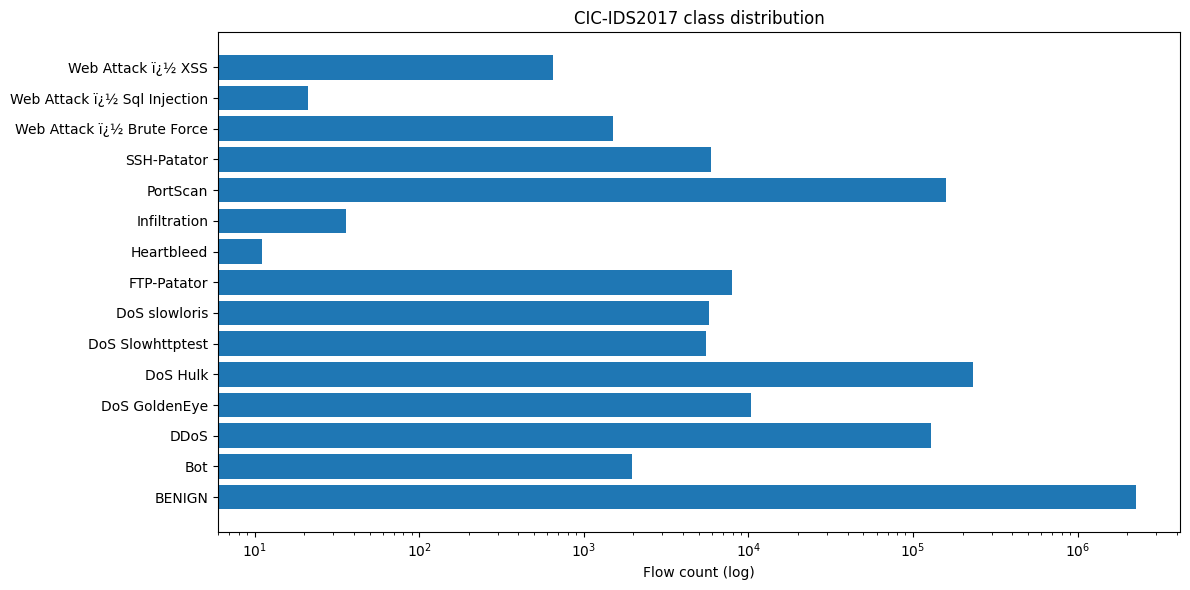

In [14]:
import matplotlib.pyplot as plt
counts=report['labels']
plt.figure(figsize=(12,6))
plt.barh(list(counts),list(counts.values()))
plt.xscale('log');plt.xlabel('Flow count (log)');plt.title('CIC-IDS2017 class distribution');plt.tight_layout()
plt.savefig(OUTPUT/'cic_classes.png');plt.show()

## Stratified exploratory sample quality checks (300 per label)

The sample is for quality inspection, not for an official leakage-safe evaluation.

In [15]:
from collections import defaultdict
from nids.datasets import CIC_FEATURES

# Deterministic, uniform per-class reservoir using random priorities.
# Each row receives an independent random key; keep the 300 smallest keys per label.
PER_LABEL = 300
rng = np.random.default_rng(42)
res = {}  # label -> DataFrame with temporary _priority column
for path in CIC_FILES:
    for chunk in pd.read_csv(path, chunksize=100_000, encoding='latin1', low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        chunk['Label'] = chunk['Label'].astype('string').str.strip()
        chunk['_priority'] = rng.random(len(chunk))
        for label, part in chunk.groupby('Label', dropna=False, sort=False):
            top = part.nsmallest(PER_LABEL, '_priority')
            if label in res:
                top = pd.concat([res[label], top], ignore_index=True).nsmallest(PER_LABEL, '_priority')
            res[label] = top

s = pd.concat(res.values(), ignore_index=True).drop(columns='_priority')
print('Sample:', s.shape, '| classes:', s['Label'].nunique())
print('Counts by label:')
print(s['Label'].value_counts().to_string())
print('Missing values in selected features:')
print(s[CIC_FEATURES].isna().sum().sort_values(ascending=False).head(10).to_string())
print('Infinity in numeric selected features:', int(np.isinf(s[CIC_FEATURES].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)).sum()))
print('Duplicated selected-feature rows:', int(s[CIC_FEATURES].duplicated().sum()))
s.to_csv(OUTPUT / 'cic_pilot_sample_300_per_label.csv', index=False)
print('Saved:', OUTPUT / 'cic_pilot_sample_300_per_label.csv')


Sample: (3668, 79) | classes: 15
Counts by label:
Label
BENIGN                          300
DDoS                            300
PortScan                        300
Bot                             300
Web Attack ï¿½ Brute Force      300
Web Attack ï¿½ XSS              300
FTP-Patator                     300
DoS GoldenEye                   300
SSH-Patator                     300
DoS slowloris                   300
DoS Slowhttptest                300
DoS Hulk                        300
Infiltration                     36
Web Attack ï¿½ Sql Injection     21
Heartbleed                       11
Missing values in selected features:
Flow Bytes/s                   4
Flow Duration                  0
Destination Port               0
Total Fwd Packets              0
Total Backward Packets         0
Total Length of Fwd Packets    0
Total Length of Bwd Packets    0
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Std                   0
Infinity in numeric selected features